# Python express pour le prudentiel

Séance 2. Une heure pour passer du tableur au code : calculer, vectoriser, manipuler un tableau de données, tracer, vérifier.
Chaque cellule s'exécute avec **Maj + Entrée**. Dans Colab, rien à installer : les données sont téléchargées depuis le dépôt du cours.

## 1. Calculer : variables et fonctions

Une fonction se nomme, se documente et se réutilise : c'est l'équivalent d'une formule Excel qu'on n'écrirait qu'une fois.

In [1]:
def valeur_actuelle(flux, taux, date):
    """Valeur actuelle d'un flux versé à la date `date` (en années), au taux annuel `taux`."""
    return flux / (1 + taux) ** date

valeur_actuelle(100, 0.03, 5)

86.2608784384164

In [2]:
# Un échéancier : une liste de flux, un flux par année
echeancier = [40, 40, 40, 1040]
sum(valeur_actuelle(f, 0.03, t) for t, f in enumerate(echeancier, start=1))

1037.1709840281035

## 2. Vectoriser avec NumPy

Au lieu de boucler sur les années, on calcule sur des vecteurs entiers : c'est plus court, plus rapide, et plus proche de l'écriture mathématique.

In [3]:
import numpy as np

flux = np.array([40, 40, 40, 1040])
dates = np.arange(1, 5)
taux = np.array([0.025, 0.028, 0.030, 0.032])   # courbe des taux zéro-coupon
(flux / (1 + taux) ** dates).sum()

np.float64(1030.3650724807023)

**Agréger des SCR avec une matrice de corrélation.** La formule standard agrège les modules par
$\mathrm{BSCR} = \sqrt{s^\top C\, s}$ (directive 2009/138/CE, annexe IV). En NumPy, le produit matriciel s'écrit `@`.

In [4]:
import pandas as pd
from pathlib import Path

# Les données sont à la racine de la séance ; sinon (Colab), on les lit sur GitHub
DEPOT = "https://raw.githubusercontent.com/FabriceBM/Compta-Prud-1/main/seances/02_excel-python-agents/"
def source(nom):
    return nom if Path(nom).exists() else DEPOT + nom

C = pd.read_csv(source("matrice-correlation.csv"), sep=";", index_col="module")
C

,marche,contrepartie,vie,sante,non_vie
module,,,,,
marche,1.00,0.25,0.25,0.25,0.25
contrepartie,0.25,1.00,0.25,0.25,0.50
vie,0.25,0.25,1.00,0.25,0.00
sante,0.25,0.25,0.25,1.00,0.00
non_vie,0.25,0.50,0.00,0.00,1.00


In [5]:
s = np.array([60, 5, 30, 0, 0])   # SCR marché, contrepartie, vie, santé, non-vie (M€)
bscr = np.sqrt(s @ C.to_numpy() @ s)
print(f"BSCR = {bscr:.2f} M€, contre {s.sum()} M€ en simple somme : la diversification vaut {s.sum() - bscr:.2f} M€")

BSCR = 75.17 M€, contre 95 M€ en simple somme : la diversification vaut 19.83 M€


## 3. Manipuler un tableau avec pandas

Un `DataFrame` est une feuille de calcul dont chaque colonne a un nom et un type. Les données sont celles du TD 2 : six assureurs fictifs, en M€.

In [6]:
d = pd.read_csv(source("bilans-assureurs.csv"), sep=";")
d

,entite,nom,actif,provisions_techniques,dettes_subordonnees,autres_passifs,excedent_declare,tier1,tier2,tier3,scr,mcr,ratio_scr_declare
0,A,Assureur Gamma,1200,1050,35,20,95,85,35,10,80.0,30,156.25
1,B,Assureur Delta,800,700,20,15,75,65,20,0,85.0,25,100.00
2,C,Assureur Epsilon,950,830,0,40,80,50,0,30,60.0,20,133.30
3,D,Assureur Zêta,1500,1320,50,30,100,100,50,0,120.0,25,125.00
4,E,Assureur Êta,600,560,10,5,25,20,10,5,40.0,12,87.50
5,F,Assureur Thêta,300,250,0,10,40,40,0,0,NaN,10,NaN


In [7]:
# Une colonne calculée, comme une formule recopiée sur toute une colonne Excel
d["excedent_recalcule"] = d["actif"] - d["provisions_techniques"] - d["dettes_subordonnees"] - d["autres_passifs"]
d[["entite", "excedent_declare", "excedent_recalcule"]]

,entite,excedent_declare,excedent_recalcule
0,A,95,95
1,B,75,65
2,C,80,80
3,D,100,100
4,E,25,25
5,F,40,40


In [8]:
# Filtrer : les lignes où le recalcul ne retrouve pas le déclaré
d[d["excedent_recalcule"] != d["excedent_declare"]][["entite", "nom", "excedent_declare", "excedent_recalcule"]]

,entite,nom,excedent_declare,excedent_recalcule
1,B,Assureur Delta,75,65


In [9]:
# Les valeurs manquantes ne disparaissent pas : on les cherche explicitement
d[d.isna().any(axis=1)][["entite", "nom", "scr", "ratio_scr_declare"]]

,entite,nom,scr,ratio_scr_declare
5,F,Assureur Thêta,NaN,NaN


## 4. Tracer

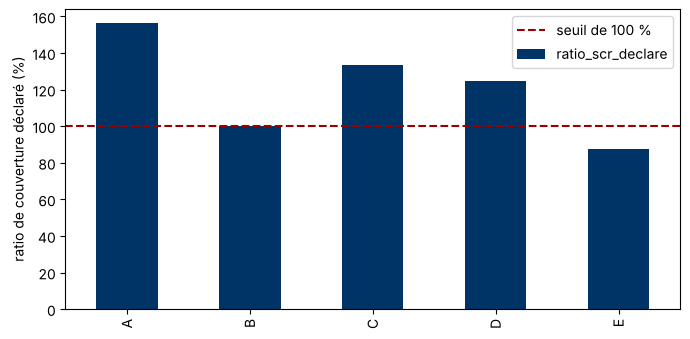

In [10]:
import matplotlib.pyplot as plt

ax = d.dropna(subset=["ratio_scr_declare"]).plot.bar(x="entite", y="ratio_scr_declare", legend=False,
                                                     color="#003366", figsize=(7, 3.5))
ax.axhline(100, color="#990000", linestyle="--", label="seuil de 100 %")
ax.set_xlabel("")
ax.set_ylabel("ratio de couverture déclaré (%)")
ax.legend()
plt.tight_layout()

Attention : ce sont les ratios **déclarés**. Le TD 2 les recalcule avec les limites d'éligibilité : l'un d'eux ne tient pas.

## 5. Vérifier

Un calcul non vérifié n'est pas un résultat. Deux réflexes :
- une **assertion** qui arrête tout si un résultat connu n'est pas retrouvé ;
- une **tolérance** pour comparer des nombres à virgule : en machine, `0.1 + 0.2 == 0.3` est faux.

In [11]:
print(0.1 + 0.2 == 0.3, np.isclose(0.1 + 0.2, 0.3))
assert np.isclose(bscr, 75.17, atol=0.01), "le BSCR ne correspond pas au calcul Excel"

False True


## 6. Et avec un agent d'IA ?

Un agent peut écrire ce code à votre place. Il ne le vérifiera pas à votre place. Avant de lui confier une tâche, écrivez :
- l'**objectif** et les **données** (fictives ou anonymisées) ;
- les **contraintes** : bibliothèques, références réglementaires à respecter, ce qu'il ne doit pas faire ;
- les **critères d'acceptation** : quels résultats exacts il doit retrouver, quelles assertions doivent passer.

Puis relisez, exécutez, rapprochez d'un calcul indépendant. C'est l'objet de la partie C du TD 2.